```markdown
# ⚙ Audio Fingerprinting & Matching System — Colab Handover Doc

Welcome Group 3! This notebook is pre-configured and ready for the **Robustness and Comparison Studies (Tasks 8, 9, and 10)**. Below is a summary of what has been successfully built and how to use the current pipeline.

---

## ✅ Summary of What's Been Done (Tasks 1–6)
1. **Audio Loading & Preprocessing**: Audio files are loaded, mixed to mono, and resampled to a unified `22,050 Hz` sample rate.
2. **Resolution Trade-Off Study**: Handled the trade-offs between temporal and spectral resolution using Short-Time Fourier Transforms (STFT) with sliding windows ($n\_fft=512$ vs. $n\_fft=2048$).
3. **Spectral Peak Extraction**: Local spectrogram maxima are filtered and mapped using a 2D max-filter neighborhood to find high-intensity peak landmarks.
4. **Constrained Peak-Pairing**: Anchor points are paired with targets inside a designated temporal forward window to establish structural fingerprint signatures: `((f1, f2, dt), t1)`.
5. **Baseline Matching Classifier**: Implemented a global cosine similarity classifier that uses the average spectral energy representation of query clips to recognize target tracks.
6. **Shazam-Style Alignment Matcher**: Configured an inverted hash-index mapping fingerprint hashes to reference tracks and offset times. Correct matches yield a high-density, singular voting peak on an offset alignment histogram.
9. **Noise Robustness**: Tests how adding different amounts of noise affects recognition.

---

## ⚙ How to use the Multi-Song Database & Focus Selector
* **Centralized Audio Reference Database (`613d39ac`)**: Add track names and file paths directly to the `paths` dictionary. It will automatically populate the database, check for empty dict configurations, and dynamically generate lookup maps.
* **Interactive Focus Selector (`7179457c`)**: Set `focus_song` to any key in your loaded database dictionary. Heavy computations (such as visual spectrograms and peak landmark connections) will dynamically target **only** this track to prevent memory/kernel crashes.
* **Auto-Indexing & Matching (`e6017190` & `dd3fc209`)**: Every track added to the database is indexed. The interactive query matching panel allows you to upload custom query clips or run simulations while matching seamlessly against the dynamic dictionary index.
```

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

from IPython.display import Audio, display

print(librosa.__version__)

0.11.0


In [ ]:
import os

# --- Step 1: Centralized Audio Reference Database ---
# Add as many reference tracks as you want here!
paths = {
    "Sample song": "/content/audio1.mp3",
    # "Second Song": "/content/another_track.mp3"  # Seamlessly add more here
}

sr = 22050
audio = {}

# Dynamic Loading
for name, path in paths.items():
    if os.path.exists(path):
        y, _ = librosa.load(path, sr=sr, mono=True)
        audio[name] = y
        print(f"Successfully loaded reference track: '{name}' | Duration: {round(len(y) / sr, 2)}s")
    else:
        print(f"☑ Warning: Path '{path}' not found for song '{name}'")

# Error handling for empty database
if not audio:
    raise ValueError("Error: The database dictionary 'audio' is empty! Please verify your file paths in the dictionary above.")

# --- Step 2: Set the Focus Song for Heavy Computations and Visualizations ---
# Simply change this variable to choose which song you want to analyze or visualize in the next blocks!
focus_song = list(audio.keys())[0]
print(f"\nActive Focus Song selected for visualization: '{focus_song}'")

Successfully loaded reference track: 'Sample song' | Duration: 236.7s

Active Focus Song selected for visualization: 'Sample song'


In [ ]:
#Uploading song and making the audio dictionary

paths = {
    "Sample song": "/content/audio1.mp3"
}

sr = 22050
audio = {}

for name, path in paths.items():
    info = sf.info(path)

    y, _ = librosa.load(path, sr=sr, mono=True)
    audio[name] = y

    print(
        name,
        "Original sample rate:", info.samplerate,
        "Original channels:", info.channels,
        "Duration:", round(len(y) / sr, 2), "seconds"
    )

Sample song Original sample rate: 44100 Original channels: 2 Duration: 236.7 seconds


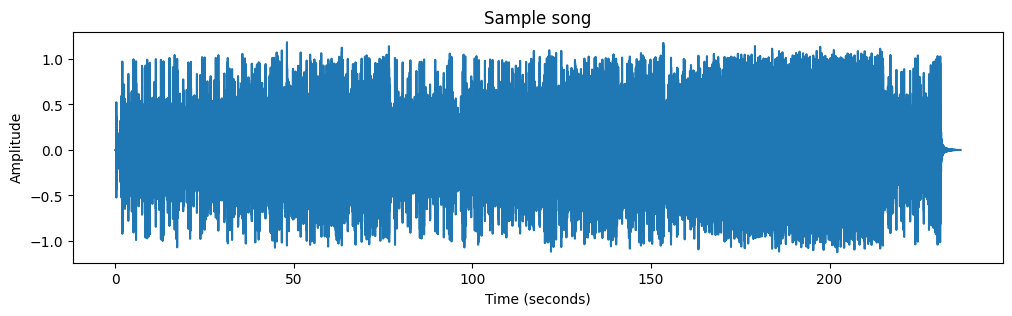

In [ ]:
#Plotting amplitude vs time

for name, y in audio.items():
    time = np.arange(len(y)) / sr

    plt.figure(figsize=(12, 3))
    plt.plot(time, y)
    plt.title(name)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.show()

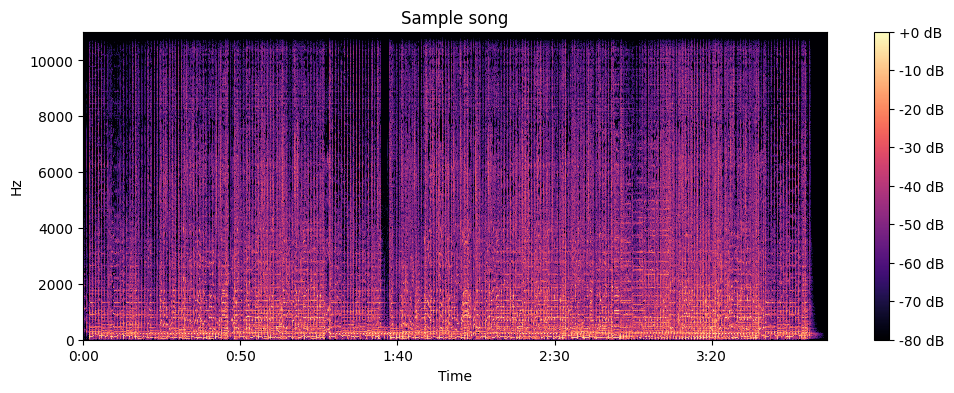

In [ ]:
#Building the Spectrogram

n_fft = 2048
hop_length = 512

for name, y in audio.items():
    S = np.abs(
        librosa.stft(
            y,
            n_fft=n_fft,
            hop_length=hop_length
        )
    )

    S_db = librosa.amplitude_to_db(S, ref=np.max)

    plt.figure(figsize=(12, 4))
    librosa.display.specshow(
        S_db,
        sr=sr,
        hop_length=hop_length,
        x_axis="time",
        y_axis="hz"
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title(name)
    plt.show()

In [ ]:
# --- Optimized Focused Spectrogram & Peak Extraction ---
# Generates spectrogram and peak landmarks ONLY for the chosen focus song to save RAM

if not audio:
    raise ValueError("Error: Reference database is empty!")
if focus_song not in audio:
    focus_song = list(audio.keys())[0]
    print(f"Warning: Focus song not found. Falling back to default: '{focus_song}'")

y_focus = audio[focus_song]
n_fft = 2048
hop_length = 512

# Calculate Spectrogram
S_focus = np.abs(librosa.stft(y_focus, n_fft=n_fft, hop_length=hop_length))
S_db_focus = librosa.amplitude_to_db(S_focus, ref=np.max)

# Identify Peaks on Focus Song
from scipy.ndimage import maximum_filter
neighbourhood = (7, 7)
local_maxima = (S_db_focus == maximum_filter(S_db_focus, size=neighbourhood))
threshold = S_db_focus.max() - 40
peak_mask = local_maxima & (S_db_focus > threshold)

freq_bins, time_bins = np.where(peak_mask)
peak_frequencies = freq_bins * sr / n_fft
peak_times = time_bins * hop_length / sr

print(f"Analysis Complete for Focus Song: '{focus_song}'")
print(f"-> Extracted {len(peak_times)} spectral peaks.")

Analysis Complete for Focus Song: 'Sample song'
-> Extracted 69834 spectral peaks.


In [ ]:
#Identifying peaks

from scipy.ndimage import maximum_filter

# Assume S_db is a spectrogram in dB
# from Step 2, with n_fft = 2048.

neighbourhood = (7, 7)

local_maxima = (
    S_db == maximum_filter(S_db, size=neighbourhood)
)

threshold = S_db.max() - 40
peak_mask = local_maxima & (S_db > threshold)

freq_bins, time_bins = np.where(peak_mask)

peak_frequencies = freq_bins * sr / n_fft
peak_times = time_bins * hop_length / sr

print("Number of detected peaks:", len(peak_times))

Number of detected peaks: 69834


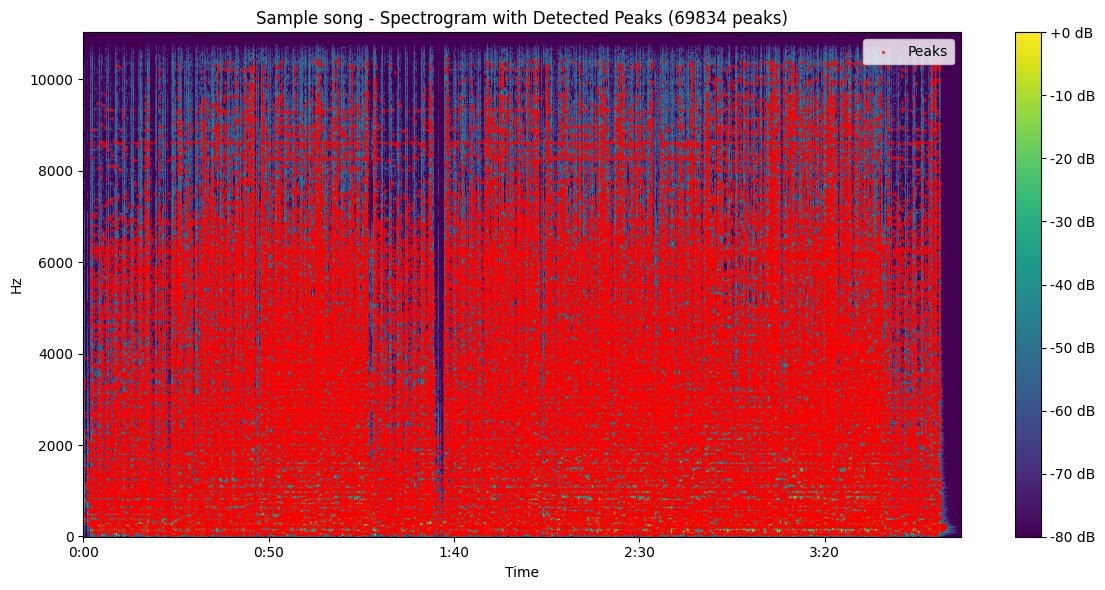

In [ ]:
# Step 3: Visualizing the Selected Peaks on the Spectrogram
plt.figure(figsize=(12, 6))

# Plot the spectrogram in dB
librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz",
    cmap='viridis'
)
plt.colorbar(format="%+2.0f dB")

# Scatter plot the detected peaks over the spectrogram
# We plot time in seconds vs frequency in Hz
plt.scatter(peak_times, peak_frequencies, color='red', s=2, alpha=0.6, label='Peaks')

plt.title(f"{name} - Spectrogram with Detected Peaks ({len(peak_times)} peaks)")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

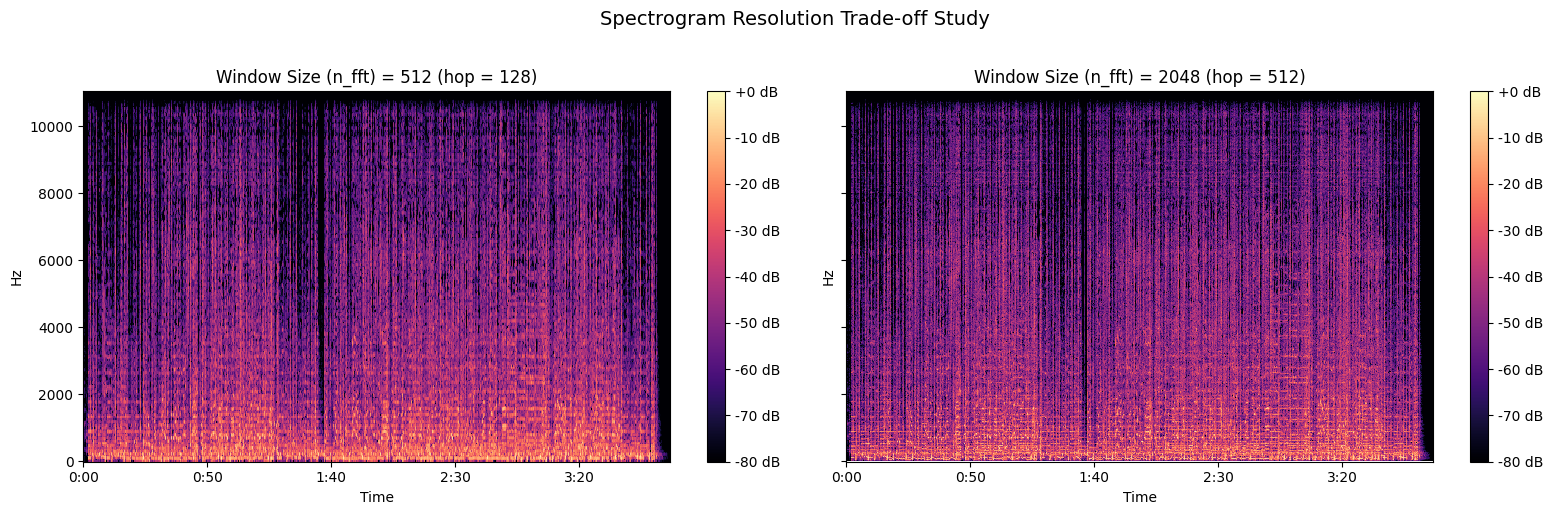

In [ ]:
# Task 2: Spectrogram and Window-Size Study
# We will compare a small window size (high time resolution, low frequency resolution)
# and a large window size (low time resolution, high frequency resolution).

window_sizes = [512, 2048]
hop_ratio = 0.25  # maintain constant overlap ratio of 75%

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

y_signal = audio["Sample song"]

for idx, n_fft_val in enumerate(window_sizes):
    hop_length_val = int(n_fft_val * hop_ratio)

    # Calculate STFT
    S_temp = np.abs(librosa.stft(y_signal, n_fft=n_fft_val, hop_length=hop_length_val))
    S_db_temp = librosa.amplitude_to_db(S_temp, ref=np.max)

    # Plot spectrogram
    img = librosa.display.specshow(
        S_db_temp,
        sr=sr,
        hop_length=hop_length_val,
        x_axis="time",
        y_axis="hz",
        ax=axes[idx]
    )
    axes[idx].set_title(f"Window Size (n_fft) = {n_fft_val} (hop = {hop_length_val})")
    fig.colorbar(img, ax=axes[idx], format="%+2.0f dB")

plt.suptitle("Spectrogram Resolution Trade-off Study", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Generated 13202959 candidate peak-pair fingerprints from 69834 peaks.


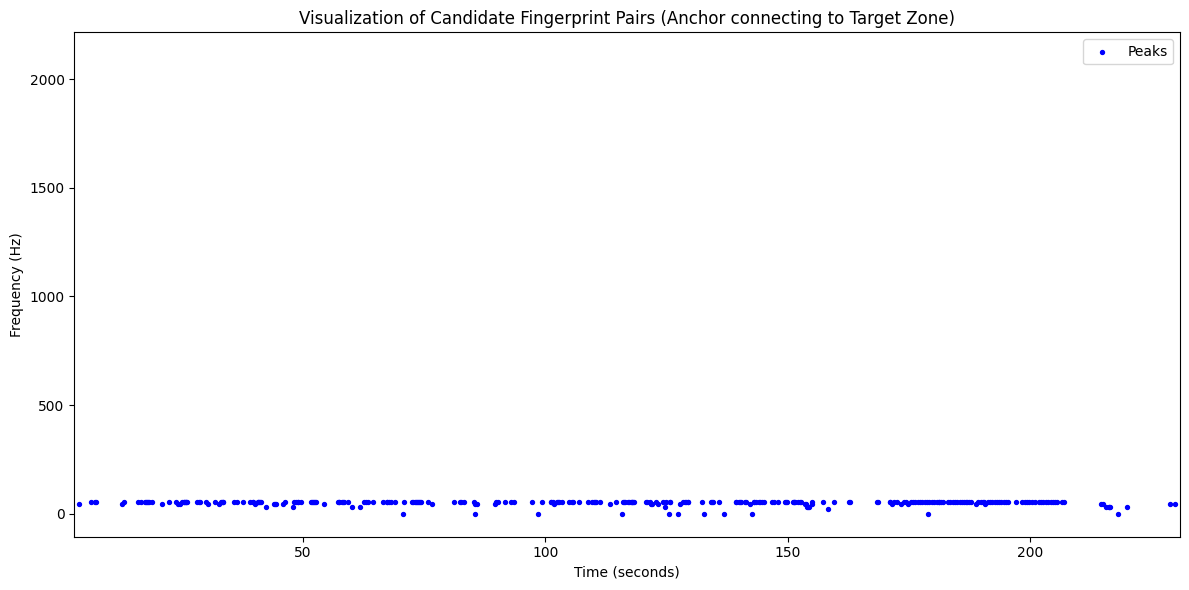

In [ ]:
# Task 4: Fingerprint Representation (Peak-Pairing)
# Sort the peak coordinates by time so we can scan forward in time

peaks = sorted(zip(peak_times, peak_frequencies), key=lambda x: x[0])

# Configuration parameters for peak pairing (Shazam Target Zones)
MIN_TIME_GAP = 0.1     # minimum time difference in seconds between paired peaks
MAX_TIME_GAP = 1.5     # maximum time difference in seconds between paired peaks
MAX_FREQ_GAP = 2000.0  # maximum frequency difference in Hz between paired peaks

fingerprints = []

# Iterate through each peak as an anchor point
for i, (t1, f1) in enumerate(peaks):
    for j in range(i + 1, len(peaks)):
        t2, f2 = peaks[j]
        dt = t2 - t1

        # Stop scanning forward if we exceed the maximum time gap
        if dt > MAX_TIME_GAP:
            break

        # Check if the pair falls inside the target zone criteria
        if dt >= MIN_TIME_GAP and abs(f2 - f1) <= MAX_FREQ_GAP:
            # Record the fingerprint pair: ((f1, f2, dt), t1)
            # We round to store them efficiently as integers/discrete values
            fingerprints.append(((int(f1), int(f2), round(dt, 2)), round(t1, 2)))

print(f"Generated {len(fingerprints)} candidate peak-pair fingerprints from {len(peaks)} peaks.")

# Let's plot a small subset of these pairs (e.g. first 150 pairs) to visualize the connections
plt.figure(figsize=(12, 6))
plt.scatter(peak_times[:300], peak_frequencies[:300], color='blue', s=8, label='Peaks', zorder=2)

# Draw connection lines for the first 150 fingerprints
plotted_lines = 0
for ((f1, f2, dt), t1) in fingerprints:
    if plotted_lines >= 150:
        break
    t2 = t1 + dt
    plt.plot([t1, t2], [f1, f2], color='red', alpha=0.3, linestyle='-', linewidth=0.8, zorder=1)
    plotted_lines += 1

plt.title("Visualization of Candidate Fingerprint Pairs (Anchor connecting to Target Zone)")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.legend()
plt.xlim(min(peak_times[:300]) - 1, max(peak_times[:300]) + 1)
plt.tight_layout()
plt.show()

In [ ]:
# --- Scalable & Safe Multi-Song Fingerprint Indexer ---
# Instead of processing all songs at once in a massive, fragile array, we index them dynamically.
from collections import defaultdict

fingerprint_index = defaultdict(list)

def compute_fingerprints_for_signal(signal, sr_rate=22050):
    S_mag = np.abs(librosa.stft(signal, n_fft=2048, hop_length=512))
    S_db_mag = librosa.amplitude_to_db(S_mag, ref=np.max)

    # Peak extraction
    local_max = (S_db_mag == maximum_filter(S_db_mag, size=(7, 7)))
    peak_mask_mag = local_max & (S_db_mag > (S_db_mag.max() - 40))
    f_bins, t_bins = np.where(peak_mask_mag)
    p_freqs = f_bins * sr_rate / 2048
    p_times = t_bins * 512 / sr_rate

    peaks_list = sorted(zip(p_times, p_freqs), key=lambda x: x[0])

    # Generate peak-pairs
    song_fingerprints = []
    for i, (t1, f1) in enumerate(peaks_list):
        connections = 0
        for j in range(i + 1, len(peaks_list)):
            t2, f2 = peaks_list[j]
            dt = t2 - t1
            if dt > 1.5:
                break
            if dt >= 0.1 and abs(f2 - f1) <= 2000.0:
                song_fingerprints.append(((int(f1), int(f2), round(dt, 2)), round(t1, 2)))
                connections += 1
                if connections >= 3: # Keep pairing dense but lightweight
                    break
    return song_fingerprints

# Automatically Index all tracks currently inside the 'audio' dictionary
print("Indexing Reference Tracks into Fingerprint Index Map...")
for track_name, signal in audio.items():
    track_fprints = compute_fingerprints_for_signal(signal, sr)
    for (signature, t_song) in track_fprints:
        fingerprint_index[signature].append((track_name, t_song))
    print(f" -> Indexed '{track_name}' with {len(track_fprints)} fingerprints.")

print(f"\nDatabase successfully updated! Total unique fingerprints in index: {len(fingerprint_index)}")

Indexing Reference Tracks into Fingerprint Index Map...
 -> Indexed 'Sample song' with 209204 fingerprints.

Database successfully updated! Total unique fingerprints in index: 155648


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# --- Step 1: Build the Reference Database using Average Spectral Features ---
# In this baseline, the feature vector is the mean magnitude spectrum across all time frames.
reference_db = {}

for name, y_signal in audio.items():
    # Calculate magnitude spectrogram
    S_mag = np.abs(librosa.stft(y_signal, n_fft=2048, hop_length=512))
    # Calculate mean along the time axis (axis 1)
    mean_spectrum = np.mean(S_mag, axis=1)
    reference_db[name] = mean_spectrum

print("Reference database built for songs:", list(reference_db.keys()))

# --- Step 2: Define a Matching Function ---
def recognize_baseline(query_audio, sr_rate=22050):
    # Extract average spectrum for the query clip
    S_query = np.abs(librosa.stft(query_audio, n_fft=2048, hop_length=512))
    query_mean = np.mean(S_query, axis=1).reshape(1, -1)

    best_match = None
    best_score = -1.0

    # Compare query with each reference song using Cosine Similarity
    for song_name, ref_mean in reference_db.items():
        ref_mean_reshaped = ref_mean.reshape(1, -1)
        similarity = cosine_similarity(query_mean, ref_mean_reshaped)[0][0]

        if similarity > best_score:
            best_score = similarity
            best_match = song_name

    return best_match, best_score

# --- Step 3: Test the baseline recognizer with a 10-second slice ---
# Let's slice a 10-second query from "Cha Cha Cha" (e.g., from second 30 to 40)
start_sec = 30
end_sec = 40
y_full = audio["Sample song"]
query_clip = y_full[int(start_sec * sr): int(end_sec * sr)]

match_name, score = recognize_baseline(query_clip, sr)
print(f"\n--- Query Evaluation ---")
print(f"Query Clip: 10 seconds sliced from 'Cha Cha Cha'")
print(f"Predicted Song Match: {match_name}")
print(f"Similarity Score (Cosine Similarity): {score:.4f}")

Reference database built for songs: ['Sample song']

--- Query Evaluation ---
Query Clip: 10 seconds sliced from 'Cha Cha Cha'
Predicted Song Match: Sample song
Similarity Score (Cosine Similarity): 0.9667


Database Indexed! Total unique fingerprint keys: 7240877

Song: Sample song
Total matching fingerprint hits: 1598982
Predicted offset: 45.0 seconds (with 514486 votes)
Ground truth starting position: 45 seconds


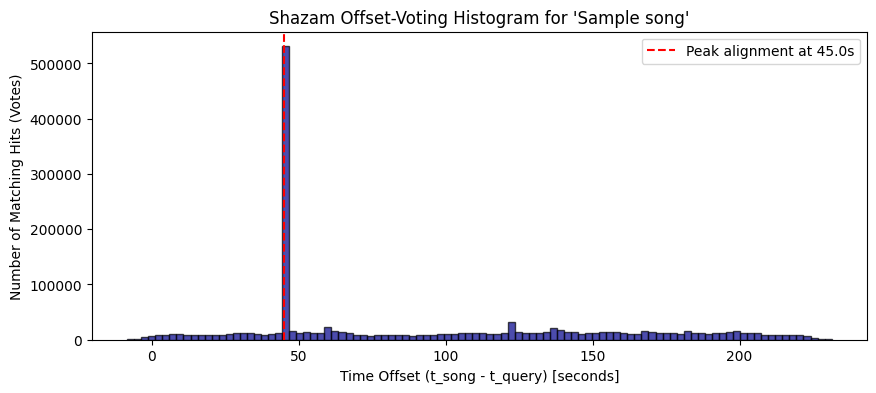

In [ ]:
from collections import defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter
import librosa

# --- Step 1: Index Reference Song Fingerprints into a Hash Map ---
# The index structure: { (f1, f2, dt): [(song_name, t_song), ...] }
fingerprint_index = defaultdict(list)

song_name = "Sample song"
for (signature, t_song) in fingerprints:
    fingerprint_index[signature].append((song_name, t_song))

print(f"Database Indexed! Total unique fingerprint keys: {len(fingerprint_index)}")

# --- Step 2: Define the Shazam-style Recognition Function ---
def recognize_shazam(query_audio, sr_rate=22050):
    # 1. Extract spectrogram and peaks from the query
    S_q = np.abs(librosa.stft(query_audio, n_fft=2048, hop_length=512))
    S_db_q = librosa.amplitude_to_db(S_q, ref=np.max)

    # Peak detection on the query clip
    local_max_q = (S_db_q == maximum_filter(S_db_q, size=(7, 7)))
    threshold_q = S_db_q.max() - 40
    peak_mask_q = local_max_q & (S_db_q > threshold_q)

    freq_bins_q, time_bins_q = np.where(peak_mask_q)
    q_peak_frequencies = freq_bins_q * sr_rate / 2048
    q_peak_times = time_bins_q * 512 / sr_rate

    q_peaks = sorted(zip(q_peak_times, q_peak_frequencies), key=lambda x: x[0])

    # 2. Pair peaks to generate query fingerprints
    query_fingerprints = []
    for i, (t1, f1) in enumerate(q_peaks):
        for j in range(i + 1, len(q_peaks)):
            t2, f2 = q_peaks[j]
            dt = t2 - t1
            if dt > 1.5:
                break
            if dt >= 0.1 and abs(f2 - f1) <= 2000.0:
                query_fingerprints.append(((int(f1), int(f2), round(dt, 2)), round(t1, 2)))

    # 3. Match against the database index and calculate offsets
    # offsets structure: { song_name: [offset1, offset2, ...] }
    offsets = defaultdict(list)

    for (signature, t_query) in query_fingerprints:
        if signature in fingerprint_index:
            for (song_name, t_song) in fingerprint_index[signature]:
                offset = t_song - t_query
                offsets[song_name].append(offset)

    return offsets

# --- Step 3: Test and Plot the Offset Histogram ---
# Let's slice a 10-second query starting at exactly 45 seconds
start_test = 45
query_clip_shazam = y_full[int(start_test * sr): int((start_test + 10) * sr)]

match_offsets = recognize_shazam(query_clip_shazam, sr)

# Analyze the results
for song, offset_list in match_offsets.items():
    print(f"\nSong: {song}")
    print(f"Total matching fingerprint hits: {len(offset_list)}")

    # Find the most common offset (the peak of the histogram)
    if len(offset_list) > 0:
        # Rounding offsets to find alignment
        rounded_offsets = np.round(offset_list, 1)
        values, counts = np.unique(rounded_offsets, return_counts=True)
        best_idx = np.argmax(counts)
        predicted_offset = values[best_idx]
        votes = counts[best_idx]

        print(f"Predicted offset: {predicted_offset} seconds (with {votes} votes)")
        print(f"Ground truth starting position: {start_test} seconds")

        # Plot the offset histogram to visualize alignment
        plt.figure(figsize=(10, 4))
        plt.hist(offset_list, bins=100, color='darkblue', edgecolor='black', alpha=0.7)
        plt.axvline(x=predicted_offset, color='red', linestyle='--', label=f'Peak alignment at {predicted_offset}s')
        plt.title(f"Shazam Offset-Voting Histogram for '{song}'")
        plt.xlabel("Time Offset (t_song - t_query) [seconds]")
        plt.ylabel("Number of Matching Hits (Votes)")
        plt.legend()
        plt.show()

###Real-World Query Matcher (With Upload Panel)

Run the cell below to load your own query audio clip. You can upload an audio file (e.g., recorded on your phone) or use a quick simulated test clip.

=== Interactive Query Matching Panel ===
Choose an option:
1. Upload your own audio clip (.mp3, .wav, .m4a, etc.)
2. Run a simulated 10-second test clip from the active database

Loaded simulated clip of 10.0s from track 'Sample song'.

--- Running Baseline Classifier on Simulated 10s Clip (from 'Sample song' starting at 60s) ---
Baseline Best Match: Sample song (Cosine Similarity: 0.9822)

--- Running Shazam-style Matcher on Simulated 10s Clip (from 'Sample song' starting at 60s) ---

Match Found for Song: 'Sample song'
 -> Aligning peak offset: 60.0 seconds
 -> Matching landmark consensus: 9831 peak-pair votes (Total hits: 34975)


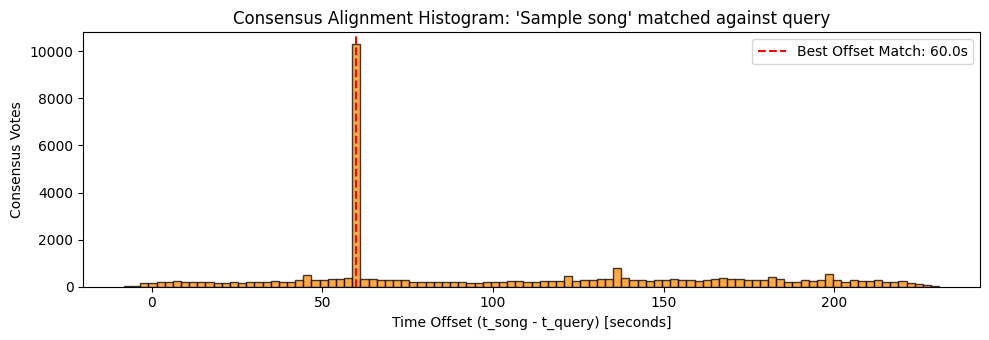

In [ ]:
import os
from google.colab import files
import numpy as np
import librosa
import matplotlib.pyplot as plt

print("=== Interactive Query Matching Panel ===")
print("Choose an option:")
print("1. Upload your own audio clip (.mp3, .wav, .m4a, etc.)")
print("2. Run a simulated 10-second test clip from the active database")

# Quick configuration
choice = "2"  # @param ["1", "2"] {type:"string"}

sr = 22050
y_query = None
query_name = ""

# Safely verify database availability
if 'audio' not in globals() or not audio:
    raise ValueError("Error: The database dictionary 'audio' is empty or not initialized. Please load at least one track first.")

# Get current active song
active_song = focus_song if ('focus_song' in globals() and focus_song in audio) else list(audio.keys())[0]

if choice == "1":
    print("\nPlease select and upload your audio file:")
    uploaded = files.upload()
    if len(uploaded) > 0:
        filename = list(uploaded.keys())[0]
        print(f"\nProcessing uploaded file: {filename}...")
        y_query, _ = librosa.load(filename, sr=sr, mono=True)
        query_name = f"Uploaded Clip ({filename})"
        os.remove(filename)
    else:
        print("No file uploaded. Falling back to option 2 (Simulated Clip).")
        choice = "2"

if choice == "2":
    start_sec = 60
    duration_sec = 10
    y_full = audio[active_song]

    # Make sure we don't slice past the track limit
    max_slice_end = min(int((start_sec + duration_sec) * sr), len(y_full))
    y_query = y_full[int(start_sec * sr): max_slice_end]
    query_name = f"Simulated {duration_sec}s Clip (from '{active_song}' starting at {start_sec}s)"
    print(f"\nLoaded simulated clip of {round(len(y_query)/sr, 2)}s from track '{active_song}'.")

if y_query is not None:
    print(f"\n--- Running Baseline Classifier on {query_name} ---")
    # Re-build reference average spectra dynamically to support multi-song databases
    reference_db = {}
    for name, y_signal in audio.items():
        S_mag = np.abs(librosa.stft(y_signal, n_fft=2048, hop_length=512))
        reference_db[name] = np.mean(S_mag, axis=1)

    best_baseline_match, baseline_score = recognize_baseline(y_query, sr)
    print(f"Baseline Best Match: {best_baseline_match} (Cosine Similarity: {baseline_score:.4f})")

    print(f"\n--- Running Shazam-style Matcher on {query_name} ---")
    match_offsets = recognize_shazam(y_query, sr)

    if len(match_offsets) == 0:
        print("No matching landmark fingerprints found in the database index!")
    else:
        for song, offset_list in match_offsets.items():
            rounded_offsets = np.round(offset_list, 1)
            values, counts = np.unique(rounded_offsets, return_counts=True)
            best_idx = np.argmax(counts)
            predicted_offset = values[best_idx]
            votes = counts[best_idx]

            print(f"\nMatch Found for Song: '{song}'")
            print(f" -> Aligning peak offset: {predicted_offset} seconds")
            print(f" -> Matching landmark consensus: {votes} peak-pair votes (Total hits: {len(offset_list)})")

            # Visualize matching histogram
            plt.figure(figsize=(10, 3.5))
            plt.hist(offset_list, bins=100, color='darkorange', edgecolor='black', alpha=0.75)
            plt.axvline(x=predicted_offset, color='red', linestyle='--', label=f'Best Offset Match: {predicted_offset}s')
            plt.title(f"Consensus Alignment Histogram: '{song}' matched against query")
            plt.xlabel("Time Offset (t_song - t_query) [seconds]")
            plt.ylabel("Consensus Votes")
            plt.legend()
            plt.tight_layout()
            plt.show()

### Spectrogram Resolution Analysis (Time vs. Frequency Trade-off)

From the generated comparison plots above, we can observe the following signal processing behaviors:

1. **Small Window Size ($n\_fft = 512$):**
   - **Time Resolution:** High. Since the window is short, we can localize rapid transitions and transient events (such as drum hits or onset times) very precisely along the x-axis.
   - **Frequency Resolution:** Low. The individual frequency bins are wide, resulting in vertical smearing or blurring of frequencies. We cannot easily distinguish nearby tone pitches.

2. **Large Window Size ($n\_fft = 2048$):**
   - **Time Resolution:** Low. Each window captures a longer duration of audio, which smears fast events horizontally along the time axis.
   - **Frequency Resolution:** High. We can clearly resolve fine vertical bands and identify distinct musical pitches and harmonics.

**Recommended Configuration:**
For general-purpose audio fingerprinting (like Shazam), a window size of **$n\_fft = 2048$** with a hop size of **$512$** is widely recommended because it offers an optimal balance that preserves enough pitch detail to construct reliable peak pairs while remaining computationally efficient.

   SNR None: 16s | Shazam correct=True votes=106970
   SNR 20: 18s | Shazam correct=True votes=84915
   SNR 10: 45s | Shazam correct=True votes=39674
   SNR 0: 46s | Shazam correct=True votes=11921
   SNR -10: 48s | Shazam correct=True votes=2742
[Sample song] trial 1/3 done  (173s elapsed)
   SNR None: 12s | Shazam correct=True votes=371655
   SNR 20: 15s | Shazam correct=True votes=245567
   SNR 10: 40s | Shazam correct=True votes=86890
   SNR 0: 44s | Shazam correct=True votes=18562
   SNR -10: 48s | Shazam correct=True votes=3341
[Sample song] trial 2/3 done  (332s elapsed)
   SNR None: 14s | Shazam correct=True votes=271722
   SNR 20: 17s | Shazam correct=True votes=178274
   SNR 10: 40s | Shazam correct=True votes=64608
   SNR 0: 45s | Shazam correct=True votes=16512
   SNR -10: 49s | Shazam correct=True votes=3170
[Sample song] trial 3/3 done  (497s elapsed)


,shazam_accuracy,baseline_accuracy,mean_votes,mean_confidence,mean_baseline_similarity,n_queries
SNR (dB),,,,,,
clean,1.0,1.0,250115.667,498.326,0.964,3
20,1.0,1.0,169585.333,303.762,0.964,3
10,1.0,1.0,63724.000,84.841,0.943,3
0,1.0,1.0,15665.000,19.536,0.787,3
-10,1.0,1.0,3084.333,4.044,0.584,3


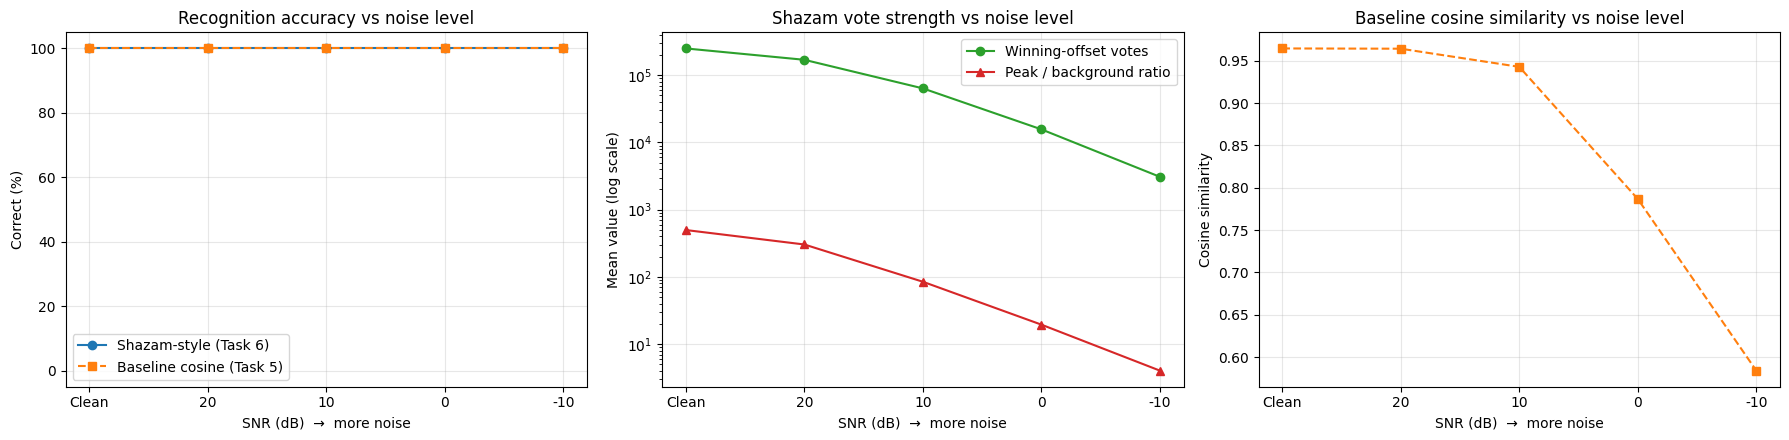

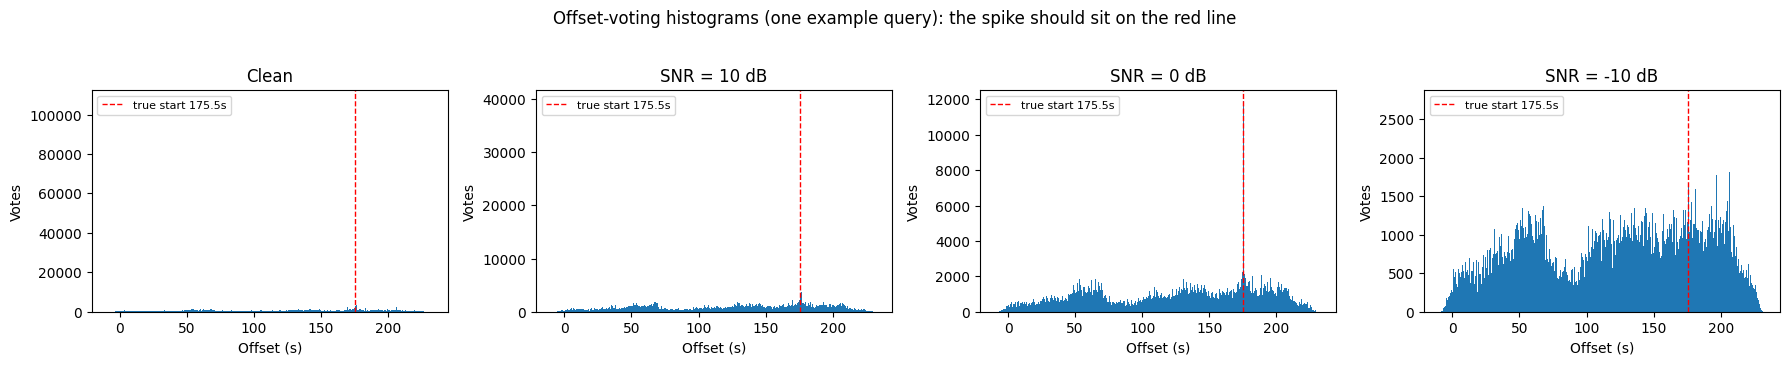

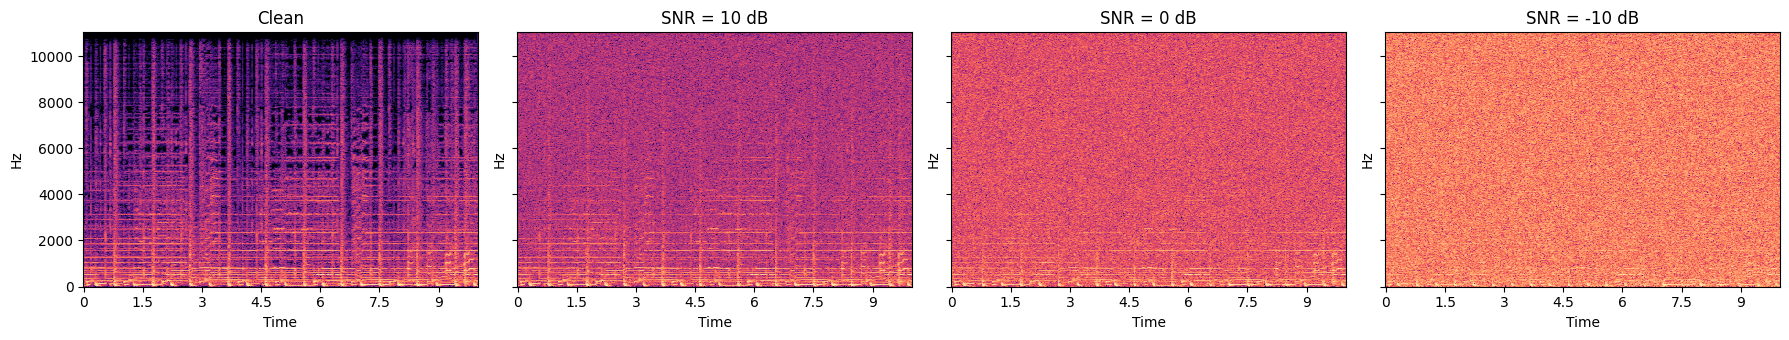

Clean


SNR = 20 dB


SNR = 10 dB


SNR = 0 dB


SNR = -10 dB


In [ ]:
# Task 9: Noise Robustness


import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- Experiment configuration ----------------
QUERY_DURATION = 10                                   # seconds per query clip
SNR_LEVELS_DB  = [None, 20, 10, 0, -10]               # None = clean (no noise); add 5 / -5 for a finer curve
N_TRIALS       = 3                                    # random start positions per song
MAX_MINUTES    = 25                                   # stop starting new trials after this long (partial results are still reported)
NOISE_TYPE     = "white"                              # "white" or "pink"
OFFSET_TOL     = 0.5                                  # seconds: allowed error in predicted offset
RNG_SEED       = 42
TEST_SONGS     = list(audio.keys())                   # songs used as query sources

# ---------------- Noise generation ----------------
def generate_noise(n_samples, kind="white", rng=None):
    rng = rng if rng is not None else np.random.default_rng()
    w = rng.standard_normal(n_samples)
    if kind == "white":
        return w
    if kind == "pink":                                # 1/f power spectrum (more like room/street noise)
        X = np.fft.rfft(w)
        f = np.fft.rfftfreq(n_samples)
        f[0] = f[1]                                   # avoid divide-by-zero at DC
        return np.fft.irfft(X / np.sqrt(f), n_samples)
    raise ValueError("kind must be 'white' or 'pink'")

def add_noise(y, snr_db, kind="white", rng=None):
    """Return y + noise scaled so that 10*log10(P_signal/P_noise) == snr_db. None -> unchanged copy."""
    if snr_db is None:
        return y.copy()
    noise = generate_noise(len(y), kind, rng)
    p_signal = np.mean(y ** 2)
    p_noise = np.mean(noise ** 2)
    scale = np.sqrt(p_signal / (p_noise * 10 ** (snr_db / 10)))
    return y + scale * noise

def measured_snr_db(clean, noisy):
    """Sanity check: SNR actually present in the noisy clip."""
    return 10 * np.log10(np.mean(clean ** 2) / np.mean((noisy - clean) ** 2))

# ---------------- Pre-flight: this cell uses YOUR Task 5 and Task 6 matchers ----------------
for _needed in ["audio", "sr", "recognize_baseline", "recognize_shazam", "fingerprint_index"]:
    if _needed not in globals():
        raise NameError(f"'{_needed}' is not defined. Run the loader cell, the Task 5 baseline cell and the Task 6 Shazam cell first.")

# ---------------- Wrapper around the Task 6 matcher ----------------
def shazam_predict(y_query):
    """Run recognize_shazam (Task 6) and summarise the offset histogram.
    Returns (song, offset, votes, confidence, (bin_values, bin_counts))."""
    offsets = recognize_shazam(y_query, sr)
    best = dict(song=None, offset=np.nan, votes=0, conf=0.0, hist=(np.array([]), np.array([])))
    for song, offs in offsets.items():
        if len(offs) == 0:
            continue
        vals, counts = np.unique(np.round(offs, 1), return_counts=True)
        i = counts.argmax()
        if counts[i] > best["votes"]:
            # confidence = winning votes / mean votes in bins away from the winner (peak-to-background)
            far = np.abs(vals - vals[i]) > 0.5
            background = counts[far].mean() if far.any() else 1.0
            best = dict(song=song, offset=float(vals[i]), votes=int(counts[i]),
                        conf=float(counts[i] / max(background, 1.0)), hist=(vals, counts))
    return best["song"], best["offset"], best["votes"], best["conf"], best["hist"]

# ---------------- Run the experiment ----------------
rng = np.random.default_rng(RNG_SEED)
query_len = int(QUERY_DURATION * sr)
records, hist_store, example_clips = [], {}, {}

t0 = time.time()
for true_song in TEST_SONGS:
    y_full_song = audio[true_song]
    max_start = len(y_full_song) - query_len
    if max_start <= 0:
        print(f"Skipping '{true_song}': shorter than {QUERY_DURATION}s")
        continue
    starts = rng.uniform(0, max_start / sr, size=N_TRIALS)          # same starts reused for every SNR

    for trial, start_sec in enumerate(starts):
        if (time.time() - t0) / 60 > MAX_MINUTES:
            print(f"Time budget of {MAX_MINUTES} min reached: stopping before trial {trial + 1}.")
            break
        clean = y_full_song[int(start_sec * sr): int(start_sec * sr) + query_len]
        for snr_db in SNR_LEVELS_DB:
            noisy = add_noise(clean, snr_db, NOISE_TYPE, rng)
            tq = time.time()

            # Task 5 baseline
            b_song, b_score = recognize_baseline(noisy, sr)

            # Task 6 Shazam-style
            s_song, s_off, s_votes, s_conf, s_hist = shazam_predict(noisy)
            s_correct = (s_song == true_song) and (abs(s_off - start_sec) <= OFFSET_TOL)

            print(f"   SNR {snr_db}: {time.time() - tq:.0f}s | Shazam correct={bool(s_correct)} votes={s_votes}")
            records.append(dict(
                song=true_song, trial=trial, start_sec=round(start_sec, 2),
                snr_db=("clean" if snr_db is None else snr_db),
                baseline_correct=(b_song == true_song), baseline_score=b_score,
                shazam_correct=bool(s_correct), shazam_votes=s_votes,
                shazam_conf=s_conf, shazam_offset=s_off,
            ))
            if trial == 0 and true_song == TEST_SONGS[0]:           # keep one example for plots
                hist_store[snr_db] = (s_hist, start_sec)
                example_clips[snr_db] = noisy
        print(f"[{true_song}] trial {trial + 1}/{N_TRIALS} done  ({time.time() - t0:.0f}s elapsed)")

results = pd.DataFrame(records)

# ---------------- Summary table ----------------
snr_order = ["clean"] + [s for s in SNR_LEVELS_DB if s is not None]
summary = (results.groupby("snr_db")
           .agg(shazam_accuracy=("shazam_correct", "mean"),
                baseline_accuracy=("baseline_correct", "mean"),
                mean_votes=("shazam_votes", "mean"),
                mean_confidence=("shazam_conf", "mean"),
                mean_baseline_similarity=("baseline_score", "mean"),
                n_queries=("shazam_correct", "size"))
           .reindex(snr_order))
summary.index.name = "SNR (dB)"
display(summary.round(3))

# ---------------- Plots ----------------
x = np.arange(len(snr_order))
xlabels = ["Clean" if s == "clean" else str(s) for s in snr_order]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(x, summary["shazam_accuracy"] * 100, "o-", label="Shazam-style (Task 6)")
axes[0].plot(x, summary["baseline_accuracy"] * 100, "s--", label="Baseline cosine (Task 5)")
axes[0].set_title("Recognition accuracy vs noise level")
axes[0].set_ylabel("Correct (%)"); axes[0].set_ylim(-5, 105); axes[0].legend()

axes[1].semilogy(x, summary["mean_votes"].clip(lower=1), "o-", color="tab:green", label="Winning-offset votes")
axes[1].semilogy(x, summary["mean_confidence"].clip(lower=1e-1), "^-", color="tab:red", label="Peak / background ratio")
axes[1].set_title("Shazam vote strength vs noise level")
axes[1].set_ylabel("Mean value (log scale)"); axes[1].legend()

axes[2].plot(x, summary["mean_baseline_similarity"], "s--", color="tab:orange")
axes[2].set_title("Baseline cosine similarity vs noise level")
axes[2].set_ylabel("Cosine similarity")

for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(xlabels)
    ax.set_xlabel("SNR (dB)  →  more noise"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---------------- Offset-voting histograms at selected SNRs ----------------
show_snrs = [s for s in [None, 10, 0, -10] if s in hist_store]
fig, axes = plt.subplots(1, len(show_snrs), figsize=(4.5 * len(show_snrs), 3.5), sharey=False)
axes = np.atleast_1d(axes)
for ax, s in zip(axes, show_snrs):
    (vals, counts), true_start = hist_store[s]
    ax.bar(vals, counts, width=0.1)
    ax.axvline(true_start, color="red", linestyle="--", linewidth=1, label=f"true start {true_start:.1f}s")
    ax.set_title("Clean" if s is None else f"SNR = {s} dB")
    ax.set_xlabel("Offset (s)"); ax.set_ylabel("Votes"); ax.legend(fontsize=8)
plt.suptitle("Offset-voting histograms (one example query): the spike should sit on the red line", y=1.03)
plt.tight_layout(); plt.show()

# ---------------- What the noisy spectrograms look like ----------------
show_snrs = [s for s in [None, 10, 0, -10] if s in example_clips]
fig, axes = plt.subplots(1, len(show_snrs), figsize=(4.5 * len(show_snrs), 3.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, s in zip(axes, show_snrs):
    S_n = librosa.amplitude_to_db(np.abs(librosa.stft(example_clips[s], n_fft=2048, hop_length=512)), ref=np.max)
    librosa.display.specshow(S_n, sr=sr, hop_length=512, x_axis="time", y_axis="hz", ax=ax)
    ax.set_title("Clean" if s is None else f"SNR = {s} dB")
plt.tight_layout(); plt.show()

# Listen to the example clips
for s, clip in example_clips.items():
    print("Clean" if s is None else f"SNR = {s} dB")
    display(Audio(clip, rate=sr))